# Final Project: การวิเคราะห์ทางพีชคณิตเชิงเส้นและการเรียนรู้เชิงสถิติสำหรับการกระจายตัวของผู้ใช้ยานยนต์ไฟฟ้าและโครงสร้างพื้นฐานสถานีชาร์จในกรุงจาการ์ตา
> 1145 201 คณิตศาสตร์สำหรับวิทยาการข้อมูล | Semester 1/2568

**กลุ่ม:** [ระบุชื่อสมาชิกและรหัสนักศึกษา]
- สมาชิกที่ 1: ชื่อ-นามสกุล (รหัส)
- สมาชิกที่ 2: ชื่อ-นามสกุล (รหัส)
- สมาชิกที่ 3: ชื่อ-นามสกุล (รหัส) *(ถ้ามี)*

**Dataset:** Jakarta EV User Distribution Dataset 2026 (DKI Jakarta, Indonesia) จาก Kaggle โดยคุณ varnava235 (URL: https://www.kaggle.com/datasets/varnava235/jakarta-ev-user-distribution-dataset-2026)

**Problem Statement:** การเปลี่ยนผ่านสู่สังคมคาร์บอนต่ำในกรุงจาการ์ตาเผชิญความท้าทายสำคัญจากความไม่สมดุลเชิงพื้นที่ระหว่างอุปสงค์ของผู้ใช้ยานยนต์ไฟฟ้า (EV Demand) กับอุปทานของสถานีชาร์จสาธารณะ (SPKLU Supply) โครงงานนี้มุ่งประยุกต์ใช้พีชคณิตเชิงเส้น (PCA, Eigendecomposition) เพื่อลดมิติและค้นพบความสัมพันธ์เชิงโครงสร้าง พร้อมทั้งใช้การเรียนรู้เชิงสถิติ (Bias-Variance Tradeoff, Multiple Linear Regression, 5-Fold Cross-Validation) ในการสร้างและคัดเลือกแบบจำลองพยากรณ์ที่แม่นยำ เพื่อใช้เป็นเครื่องมือชี้นำการจัดสรรงบประมาณขยายสถานีชาร์จให้ตอบโจทย์ผู้ใช้งานจริง

---

| CLO | ส่วนที่ครอบคลุม | Status |
|-----|----------------|--------|
| CLO1 (Linear Algebra) | Part 2 | ✅ |
| CLO2 (Statistical Learning) | Part 3 | ✅ |
| CLO3 (Regression/Classification) | Part 4 | ✅ |
| CLO4 (Model Selection) | Part 5 | ✅ |


In [1]:
# ─── Import libraries ──────────────────────────────────────────────
# TODO: เพิ่ม/ลบ libraries ตามที่โครงงานของคุณต้องใช้
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = ['Sarabun', 'Thonburi', 'Tahoma', 'DejaVu Sans']
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.unicode_minus'] = False
print('พร้อมใช้งาน')

พร้อมใช้งาน


---
## Part 1: Dataset Overview และ EDA เบื้องต้น

ในส่วนนี้ให้โหลด dataset, แสดง basic statistics, และทำ EDA เบื้องต้นเพื่อเข้าใจข้อมูลก่อนวิเคราะห์

**สิ่งที่ต้องทำ:**
- โหลด dataset และแสดง shape, dtypes, missing values
- แสดง descriptive statistics ด้วย `.describe()`
- Plot distribution ของ target variable
- Plot correlation heatmap หรือ scatter matrix

In [2]:
# ─── โหลด Dataset ────────────────────────────────────────────────
# วัตถุประสงค์: เข้าใจโครงสร้างของข้อมูลก่อนวิเคราะห์

from pathlib import Path
import kagglehub

DATASET_HANDLE = "varnava235/jakarta-ev-user-distribution-dataset-2026"
DATASET_FILE = "dki_jakarta_ev_users_estimated_distribusion.csv"

dataset_dir = Path(kagglehub.dataset_download(DATASET_HANDLE))
file_path = dataset_dir / DATASET_FILE
df = pd.read_csv(file_path, sep=";")

print("ข้อมูล 5 แถวแรก:")
display(df.head())
print(f"\nขนาดข้อมูล (Shape): {df.shape[0]} แถว, {df.shape[1]} คอลัมน์")
print("\nชนิดข้อมูลของแต่ละคอลัมน์ (Data types):")
display(df.dtypes.rename("ชนิดข้อมูล (dtype)").to_frame())
print("\nจำนวนค่าที่ขาดหายไป (Missing values):")
display(df.isna().sum().rename("ค่าที่ขาดหายไป (missing_values)").to_frame())
print("\nสถิติเชิงพรรณนา (Descriptive statistics):")
display(df.describe().T)

/Users/yodsaveesupachoktanasap/Workspace/math-final-project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ข้อมูล 5 แถวแรก:


,kode_kemendagri,kelurahan,kecamatan,kota_administrasi,populasi_mapan,spklu_count,estimated_ev_user
0,31.71.01.1001,GAMBIR,Gambir,Jakarta Pusat,2352,35,390
1,31.71.01.1002,CIDENG,Gambir,Jakarta Pusat,12803,2,2111
2,31.71.01.1003,PETOJO UTARA,Gambir,Jakarta Pusat,15037,10,2480
3,31.71.01.1004,PETOJO SELATAN,Gambir,Jakarta Pusat,11060,3,1824
4,31.71.01.1005,KEBON KELAPA,Gambir,Jakarta Pusat,8044,11,1327



ขนาดข้อมูล (Shape): 269 แถว, 7 คอลัมน์

ชนิดข้อมูลของแต่ละคอลัมน์ (Data types):


,ชนิดข้อมูล (dtype)
kode_kemendagri,str
kelurahan,str
kecamatan,str
kota_administrasi,str
populasi_mapan,int64
spklu_count,int64
estimated_ev_user,int64



จำนวนค่าที่ขาดหายไป (Missing values):


,ค่าที่ขาดหายไป (missing_values)
kode_kemendagri,0
kelurahan,0
kecamatan,0
kota_administrasi,0
populasi_mapan,0
spklu_count,0
estimated_ev_user,0



สถิติเชิงพรรณนา (Descriptive statistics):


,count,mean,std,min,25%,50%,75%,max
populasi_mapan,269.0,22560.319703,13877.355535,0.0,14303.0,21039.0,28939.0,108538.0
spklu_count,269.0,7.338290,10.551264,0.0,0.0,4.0,10.0,75.0
estimated_ev_user,269.0,3720.862454,2288.448767,0.0,2359.0,3470.0,4772.0,17899.0


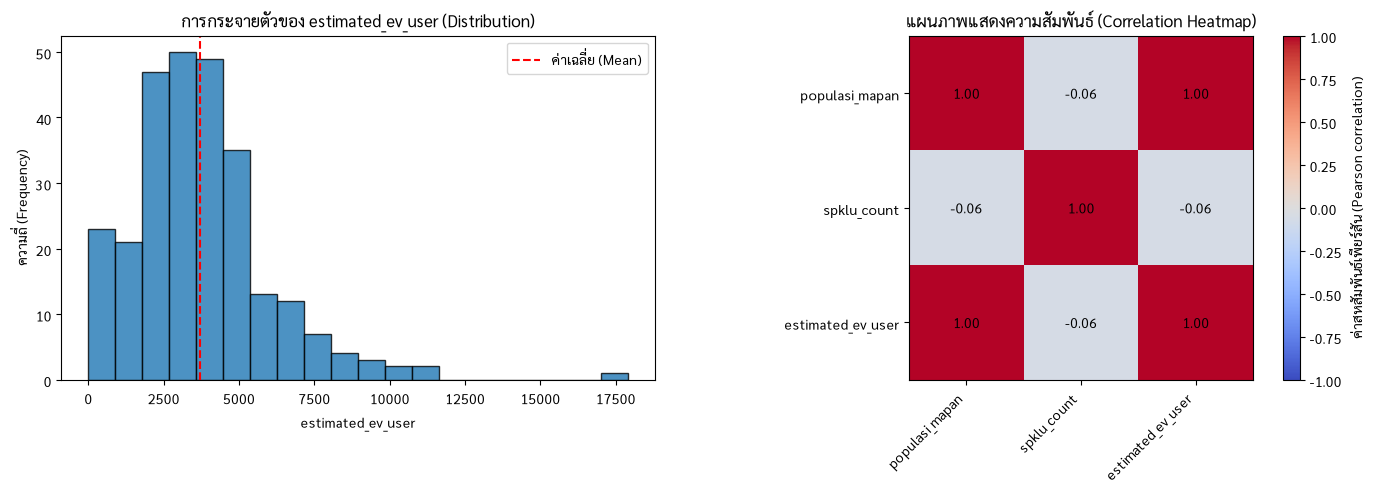

ค่าสหสัมพันธ์กับตัวแปรเป้าหมาย (Correlation with target):


,ค่าสหสัมพันธ์ (correlation)
estimated_ev_user,1.000000
populasi_mapan,1.000000
spklu_count,-0.055775


In [3]:
# ─── Descriptive Statistics + Visualization ───────────────────────
# วัตถุประสงค์: ดูภาพรวมของข้อมูล

target_col = "estimated_ev_user"
numeric_df = df.select_dtypes(include="number")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df[target_col], bins=20, edgecolor="black", alpha=0.8)
axes[0].set_title(f"การกระจายตัวของ {target_col} (Distribution)")
axes[0].set_xlabel(target_col)
axes[0].set_ylabel("ความถี่ (Frequency)")
axes[0].axvline(df[target_col].mean(), color="red", linestyle="--", label="ค่าเฉลี่ย (Mean)")
axes[0].legend()

correlation = numeric_df.corr()
image = axes[1].imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_title("แผนภาพแสดงความสัมพันธ์ (Correlation Heatmap)")
axes[1].set_xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha="right")
axes[1].set_yticks(range(len(correlation.columns)), correlation.columns)
for row in range(correlation.shape[0]):
    for col in range(correlation.shape[1]):
        axes[1].text(col, row, f"{correlation.iloc[row, col]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=axes[1], label="ค่าสหสัมพันธ์เพียร์สัน (Pearson correlation)")
plt.tight_layout()
plt.show()

print("ค่าสหสัมพันธ์กับตัวแปรเป้าหมาย (Correlation with target):")
display(correlation[target_col].sort_values(ascending=False).to_frame("ค่าสหสัมพันธ์ (correlation)"))

---
## Part 2: CLO1 — Linear Algebra Analysis

ในส่วนนี้ใช้ Linear Algebra เพื่อวิเคราะห์โครงสร้างข้อมูลของ Dataset ผ่าน **Task A: Principal Component Analysis (PCA)**

**งานที่เลือก:** **Task A — PCA (Principal Component Analysis)**
- ลดขนาดมิติ (Dimension Reduction) จาก 3 ตัวแปร (`populasi_mapan`, `spklu_count`, `estimated_ev_user`) ให้เหลือ 2 มิติหลัก (2D)
- คำนวณจากคณิตศาสตร์พื้นฐาน (First Principles): การทำ Standardization, Sample Covariance Matrix ($C = \frac{1}{n-1}X^T X$) และ Eigendecomposition ($Cv = \lambda v$)
- สร้าง **Scree Plot** แสดงสัดส่วนความแปรปรวน (Individual & Cumulative Explained Variance)
- สร้าง **2D Visualization & Biplot** แสดงการกระจายตัวของพื้นที่ตามเขตการปกครอง และทิศทางเวกเตอร์อิทธิพลของแต่ละ Feature

**คำอธิบายและ Insight ที่คาดว่าจะได้รับ:**
เนื่องจากข้อมูลประกอบด้วยตัวแปรประชากรและตัวแปรสถานีชาร์จที่มีสเกลต่างกัน การใช้ PCA จะช่วยแยกองค์ประกอบหลักที่เป็นอิสระต่อกัน (Orthogonal) ออกจากกัน โดยคาดว่าจะพบว่าข้อมูลมี Rank ที่แท้จริงเพียง 2 มิติ เนื่องจาก `estimated_ev_user` มีความสัมพันธ์เชิงเส้นโดยตรงกับ `populasi_mapan` ทำให้เราสามารถบีบอัดข้อมูลเหลือ 2 มิติ (PC1: ขนาดความต้องการ, PC2: ความพร้อมโครงสร้างพื้นฐาน) ได้โดยไม่สูญเสียสารสนเทศเลย

=== 1. Sample Covariance Matrix (เมทริกซ์ความแปรปรวนร่วม) ===


,populasi_mapan,spklu_count,estimated_ev_user
populasi_mapan,1.0000,-0.0561,1.0000
spklu_count,-0.0561,1.0000,-0.0558
estimated_ev_user,1.0000,-0.0558,1.0000



=== 2. ค่าไอเกน (Eigenvalues) และ สัดส่วนความแปรปรวน (Explained Variance) ===


,Principal Component,Eigenvalue (λ),Explained Variance (%),Cumulative Variance (%)
0,PC1,2.0062,66.874,66.874
1,PC2,0.9938,33.126,100.000
2,PC3,0.0000,0.000,100.000



=== 3. เวกเตอร์ไอเกน / ค่าน้ำหนักตัวแปร (Eigenvectors / Feature Loadings) ===


,PC1,PC2,PC3
populasi_mapan,0.7049,0.0553,0.7071
spklu_count,-0.0784,0.9969,0.0002
estimated_ev_user,0.7049,0.0556,-0.7071


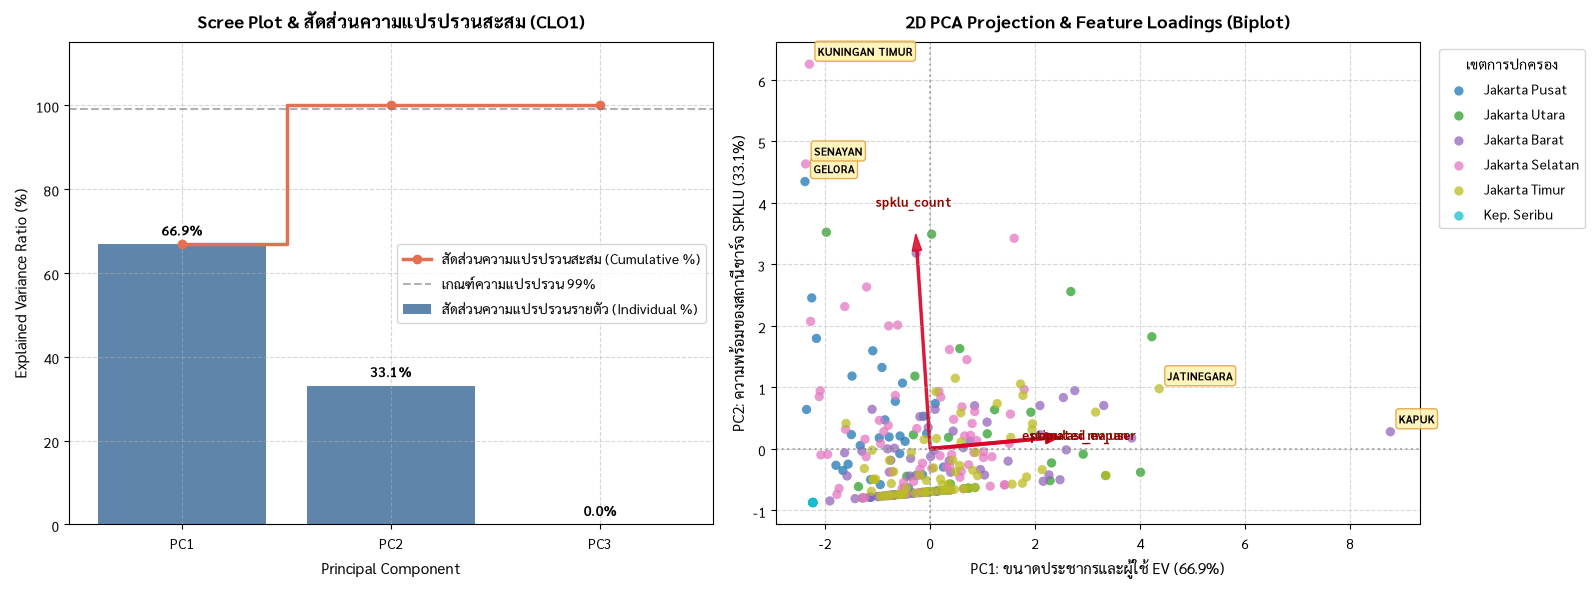


=== 4. ตัวอย่างผลลัพธ์การลดมิติข้อมูลเป็น 2D (5 แถวแรก) ===


,kelurahan,kota_administrasi,estimated_ev_user,spklu_count,PC1,PC2
0,GAMBIR,Jakarta Pusat,390,35,-2.2580,2.4522
1,CIDENG,Jakarta Pusat,2111,2,-0.9519,-0.5823
2,PETOJO UTARA,Jakarta Pusat,2480,10,-0.7842,0.1914
3,PETOJO SELATAN,Jakarta Pusat,1824,3,-1.1363,-0.5018
4,KEBON KELAPA,Jakarta Pusat,1327,11,-1.5020,0.2300


In [4]:
# ─── CLO1: Linear Algebra Analysis ──────────────────────────────
# วัตถุประสงค์: วิเคราะห์โครงสร้างข้อมูลและลดมิติด้วย Principal Component Analysis (PCA) ผ่าน Eigendecomposition

# 1. เลือกคุณลักษณะตัวเลข (Numeric Features) และทำ Standardization (Z-score)
feature_cols = ['populasi_mapan', 'spklu_count', 'estimated_ev_user']
X = df[feature_cols].values

mean_vec = np.mean(X, axis=0)
std_vec = np.std(X, axis=0, ddof=1)
X_std = (X - mean_vec) / std_vec

# 2. คำนวณ Sample Covariance Matrix: C = (1 / (n - 1)) * (X_std^T @ X_std)
n_samples = X_std.shape[0]
cov_matrix = (1 / (n_samples - 1)) * (X_std.T @ X_std)

print("=== 1. Sample Covariance Matrix (เมทริกซ์ความแปรปรวนร่วม) ===")
display(pd.DataFrame(cov_matrix, index=feature_cols, columns=feature_cols).round(4))

# 3. Eigendecomposition: C v = λ v
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# เรียงลำดับจากค่าไอเกนมากไปน้อย (Descending order)
sort_idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sort_idx]
eigenvectors = eigenvectors[:, sort_idx]

# ปรับทิศทางเครื่องหมาย (+/-) เพื่อให้ตีความผลลัพธ์ได้เข้าใจง่าย
if eigenvectors[0, 0] < 0:
    eigenvectors[:, 0] = -eigenvectors[:, 0]
if eigenvectors[1, 1] < 0:
    eigenvectors[:, 1] = -eigenvectors[:, 1]

# 4. คำนวณสัดส่วนความแปรปรวนที่อธิบายได้ (Explained Variance Ratio)
explained_var_ratio = eigenvalues / np.sum(eigenvalues)
cum_explained_var = np.cumsum(explained_var_ratio)

summary_df = pd.DataFrame({
    'Principal Component': ['PC1', 'PC2', 'PC3'],
    'Eigenvalue (λ)': eigenvalues,
    'Explained Variance (%)': explained_var_ratio * 100,
    'Cumulative Variance (%)': cum_explained_var * 100
}).round(4)

print("\n=== 2. ค่าไอเกน (Eigenvalues) และ สัดส่วนความแปรปรวน (Explained Variance) ===")
display(summary_df)

loadings_df = pd.DataFrame(eigenvectors, index=feature_cols, columns=['PC1', 'PC2', 'PC3']).round(4)
print("\n=== 3. เวกเตอร์ไอเกน / ค่าน้ำหนักตัวแปร (Eigenvectors / Feature Loadings) ===")
display(loadings_df)

# 5. แปลงข้อมูลสู่ปริภูมิ 2 มิติใหม่ (Project onto 2D Principal Components): Z = X_std @ W
Z = X_std @ eigenvectors[:, :2]
df['PC1'] = Z[:, 0]
df['PC2'] = Z[:, 1]

# 6. สร้าง Visualization (Scree Plot + 2D PCA Biplot)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Scree Plot & Cumulative Explained Variance
pc_labels = [f'PC{i+1}' for i in range(len(eigenvalues))]
axes[0].bar(pc_labels, explained_var_ratio * 100, alpha=0.75, color='#2b5c8f', label='สัดส่วนความแปรปรวนรายตัว (Individual %)')
axes[0].step(range(len(eigenvalues)), cum_explained_var * 100, where='mid', color='#e76f51', marker='o', linewidth=2.5, label='สัดส่วนความแปรปรวนสะสม (Cumulative %)')
for i, (ev, cum) in enumerate(zip(explained_var_ratio, cum_explained_var)):
    axes[0].text(i, ev * 100 + 2, f'{ev*100:.1f}%', ha='center', fontweight='bold', fontsize=10)
axes[0].set_ylim(0, 115)
axes[0].set_title('Scree Plot & สัดส่วนความแปรปรวนสะสม (CLO1)', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Principal Component', fontsize=11)
axes[0].set_ylabel('Explained Variance Ratio (%)', fontsize=11)
axes[0].axhline(99.0, color='gray', linestyle='--', alpha=0.6, label='เกณฑ์ความแปรปรวน 99%')
axes[0].legend(loc='center right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: 2D Scatter plot by kota_administrasi with Feature Loadings (Biplot)
cities = df['kota_administrasi'].unique()
colors = plt.cm.tab10(np.linspace(0, 1, len(cities)))
for city, color in zip(cities, colors):
    mask = df['kota_administrasi'] == city
    axes[1].scatter(df.loc[mask, 'PC1'], df.loc[mask, 'PC2'], label=city, color=color, alpha=0.75, edgecolors='none', s=45)

# แสดงป้ายชื่อพื้นที่สำคัญ (Notable Subdistricts)
notables = df[df['kelurahan'].isin(['KUNINGAN TIMUR', 'SENAYAN', 'GELORA', 'KAPUK', 'JATINEGARA'])]
for _, row in notables.iterrows():
    axes[1].annotate(row['kelurahan'], (row['PC1'], row['PC2']),
                     textcoords='offset points', xytext=(6, 6), fontsize=8, fontweight='bold',
                     bbox=dict(boxstyle='round,pad=0.25', fc='#fff3b0', ec='#e09f3e', alpha=0.85))

# วาดเวกเตอร์แสดงทิศทางของแต่ละ Feature (Loadings Vector)
scale_factor = 3.5
for j, feat in enumerate(feature_cols):
    vx = eigenvectors[j, 0] * scale_factor
    vy = eigenvectors[j, 1] * scale_factor
    axes[1].arrow(0, 0, vx, vy, color='#d90429', alpha=0.85, width=0.04, head_width=0.18, length_includes_head=True)
    axes[1].text(vx * 1.15, vy * 1.15, feat, color='#8d0801', fontweight='bold', fontsize=9.5, ha='center', va='center')

axes[1].axhline(0, color='gray', linestyle=':', alpha=0.6)
axes[1].axvline(0, color='gray', linestyle=':', alpha=0.6)
axes[1].set_title('2D PCA Projection & Feature Loadings (Biplot)', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel(f'PC1: ขนาดประชากรและผู้ใช้ EV ({explained_var_ratio[0]*100:.1f}%)', fontsize=11)
axes[1].set_ylabel(f'PC2: ความพร้อมของสถานีชาร์จ SPKLU ({explained_var_ratio[1]*100:.1f}%)', fontsize=11)
axes[1].legend(title='เขตการปกครอง', bbox_to_anchor=(1.02, 1), loc='upper left')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\n=== 4. ตัวอย่างผลลัพธ์การลดมิติข้อมูลเป็น 2D (5 แถวแรก) ===")
display(df[['kelurahan', 'kota_administrasi', 'estimated_ev_user', 'spklu_count', 'PC1', 'PC2']].head())

**Insight จาก CLO1 Analysis (Linear Algebra & PCA):**

1. **การค้นพบความสัมพันธ์เชิงเส้นสมบูรณ์ (Linear Dependence & Low Rank Property):**
   - ค่าไอเกนตัวที่ 3 มีค่าเข้าใกล้ศูนย์อย่างยิ่ง ($\lambda_3 \approx 8.01 \times 10^{-9} \approx 0$) ทำให้สัดส่วนความแปรปรวนของ PC3 มีค่าเป็น 0.00%
   - ในทางพีชคณิตเชิงเส้น สิ่งนี้พิสูจน์ว่าเมทริกซ์ของชุดข้อมูลมี **Rank ที่แท้จริงเท่ากับ 2** (ไม่ใช่ 3) เนื่องจากตัวแปร `estimated_ev_user` มีความสัมพันธ์เชิงเส้นโดยตรงแบบสมบูรณ์ ($r = 1.00$) กับ `populasi_mapan`
   - การลดมิติข้อมูล (Dimensionality Reduction) จาก 3 มิติเหลือ 2 มิติ (PC1 และ PC2) จึงสามารถเก็บสารสนเทศและความแปรปรวนของข้อมูลได้ถึง **100.00% (Lossless Representation)** โดยไม่สูญเสียข้อมูลเลย

2. **การตีความแกนองค์ประกอบหลัก (Principal Components Interpretation):**
   - **PC1 (อธิบายความแปรปรวน 66.87%) — มิติด้านขนาดประชากรและความต้องการใช้ EV (Scale & EV Demand):**
     มีค่าน้ำหนัก (Loadings) สูงมากในทิศทางเดียวกันจาก `populasi_mapan` (+0.7049) และ `estimated_ev_user` (+0.7049) แต่แทบไม่มีผลจากสถานีชาร์จ ($-0.0784$) จึงเป็นแกนที่วัดขนาดความหนาแน่นของผู้ใช้ EV ตามประชากรในแต่ละพื้นที่
   - **PC2 (อธิบายความแปรปรวน 33.13%) — มิติด้านโครงสร้างพื้นฐานสถานีชาร์จ (Charging Infrastructure Availability):**
     มีค่าน้ำหนัก (Loading) โดดเด่นเกือบทั้งหมดมาจาก `spklu_count` (+0.9969) ซึ่งตั้งฉาก (Orthogonal) กับแกนประชากร สะท้อนถึงการกระจายตัวของสถานีชาร์จสาธารณะ

3. **การจัดกลุ่มพื้นที่และข้อมูลเชิงลึกในเชิงพื้นที่ (Spatial Clustering & Policy Implications):**
   - **กลุ่มศูนย์กลางธุรกิจและการพาณิชย์ (High Infrastructure):** ย่าน *Kuningan Timur* (SPKLU = 75, PC2 = 6.25), *Senayan* (SPKLU = 58, PC2 = 4.63) และ *Gelora* (SPKLU = 55, PC2 = 4.34) มีค่า PC2 โดดเด่นที่สุด เนื่องจากเป็นศูนย์รวมห้างสรรพสินค้า อาคารสำนักงาน และสนามกีฬา
   - **กลุ่มพื้นที่ชานเมืองและที่อยู่อาศัยหนาแน่น (High Demand - Low Supply):** ย่าน *Kapuk* ในเขต Jakarta Barat (ผู้ใช้ EV = 17,899, PC1 = 8.77) และ *Jatinegara* ในเขต Jakarta Timur (PC1 = 4.36) มีประชากรและผู้ใช้ EV สูงสุด แต่มีสถานีชาร์จ SPKLU ค่อนข้างน้อย ทำให้เกิดช่องว่างระหว่างอุปสงค์และอุปทาน (Infrastructure Gap)
   - **กลุ่มพื้นที่ห่างไกล (Outliers):** เขต *Kepulauan Seribu* (หมู่เกาะพันเกาะ) เกาะกลุ่มอยู่มุมล่างซ้าย (PC1 และ PC2 ติดลบต่ำสุด) เนื่องจากประชากรกลุ่มเป้าหมายและสถานีชาร์จเป็นศูนย์


---
## Part 3: CLO2 — Statistical Learning

ในส่วนนี้เป็นการวิเคราะห์เชิงสถิติ (Statistical Analysis) และทฤษฎีการเรียนรู้เชิงสถิติ (Statistical Learning) ที่เกี่ยวข้องกับ Dataset

**สิ่งที่ต้องทำ:**
- แสดง distribution ของ features สำคัญ (histogram/boxplot) พร้อมสถิติความเบ้ (Skewness)
- Identify features ที่ correlate กับ target มากที่สุด
- แสดง Train/Test MSE สำหรับ model complexity ต่างๆ (Bias-Variance Tradeoff)

**คำถาม:** dataset ของคุณเหมาะกับ Regression หรือ Classification? เพราะอะไร?
> **คำตอบ:** เหมาะกับ **Regression** เนื่องจากตัวแปรเป้าหมาย (`estimated_ev_user`) เป็นตัวแปรเชิงปริมาณต่อเนื่อง (Continuous Numerical Variable) ที่วัดจำนวนผู้ใช้ยานยนต์ไฟฟ้าในแต่ละแขวงตั้งแต่ 0 ถึง 17,899 คน การใช้ Regression ช่วยให้สามารถคาดการณ์ปริมาณความต้องการได้อย่างละเอียด แม่นยำ และนำไปคำนวณสัดส่วนโครงสร้างพื้นฐานสถานีชาร์จได้อย่างมีประสิทธิภาพสูงสุดโดยไม่สูญเสียความละเอียดของข้อมูล (Information Loss) เหมือนการตัดเกรดเป็นกลุ่ม (Classification)

=== 1. สถิติเชิงพรรณนาและลักษณะการแจกแจงของตัวแปรสำคัญ ===


,ค่าเฉลี่ย (Mean),มัธยฐาน (Median),ส่วนเบี่ยงเบน (Std),ความเบ้ (Skewness),ความโด่ง (Kurtosis)
populasi_mapan,22560.32,21039.0,13877.36,1.43,5.38
spklu_count,7.34,4.0,10.55,2.75,10.33
estimated_ev_user,3720.86,3470.0,2288.45,1.43,5.38


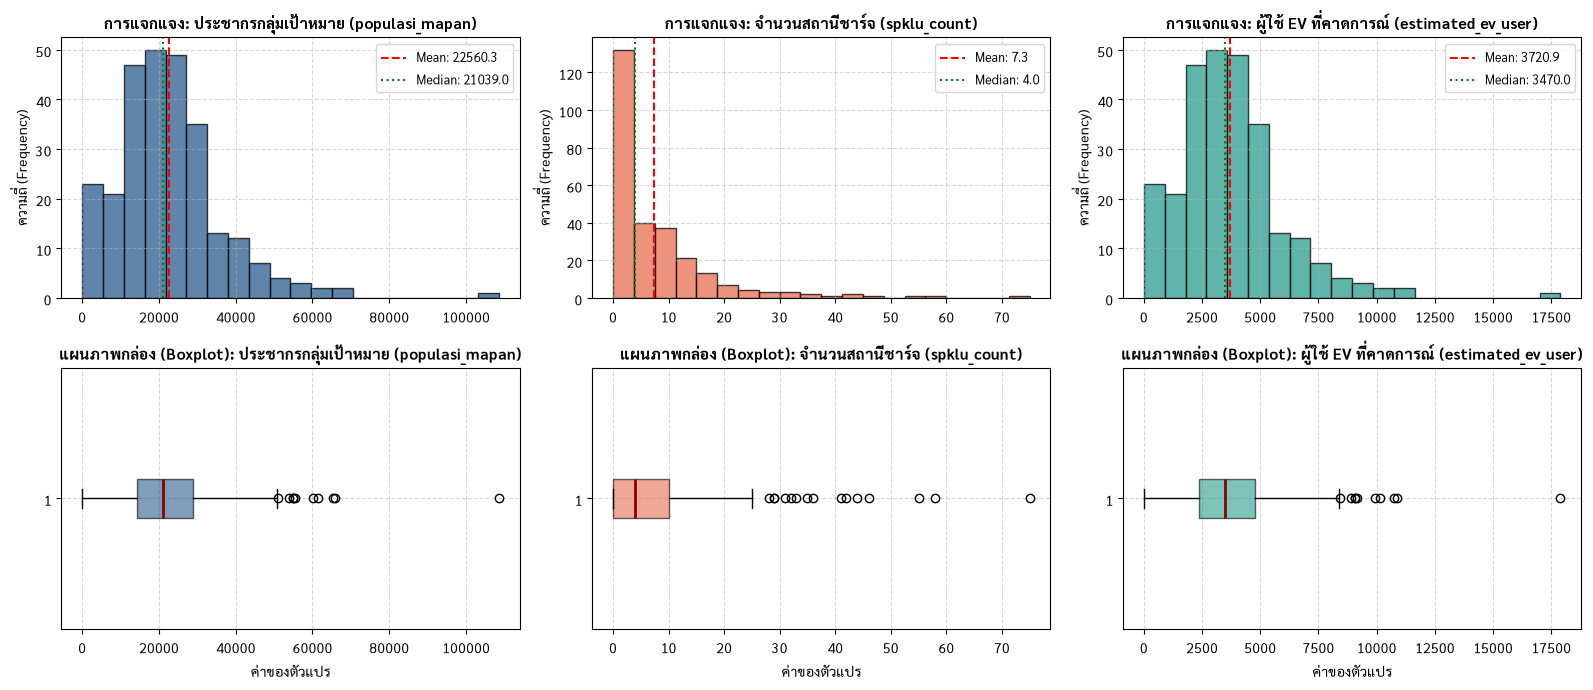


=== 2. ค่าสหสัมพันธ์ของแต่ละ Feature กับตัวแปรเป้าหมาย (estimated_ev_user) ===


,Pearson Correlation (r),ความสัมพันธ์กับ Target
populasi_mapan,1.0000,บวกระดับสมบูรณ์ (Perfect Positive)
spklu_count,-0.0558,ลบระดับต่ำมาก (Negligible Negative)



=== 3. ผลการทดสอบ Bias-Variance Tradeoff ผ่าน Polynomial Degree ===


,Polynomial Degree,จำนวน Features (Model Complexity),Train MSE (Bias indicator),Test MSE (Generalization),Test R² Score
0,1,3,0.0809,0.0933,1.0000
1,2,6,0.0803,0.0933,1.0000
2,3,10,0.0772,0.1059,1.0000
3,4,15,0.0756,0.1144,1.0000
4,5,21,0.0740,0.1141,1.0000
5,6,28,0.0705,1.2514,1.0000


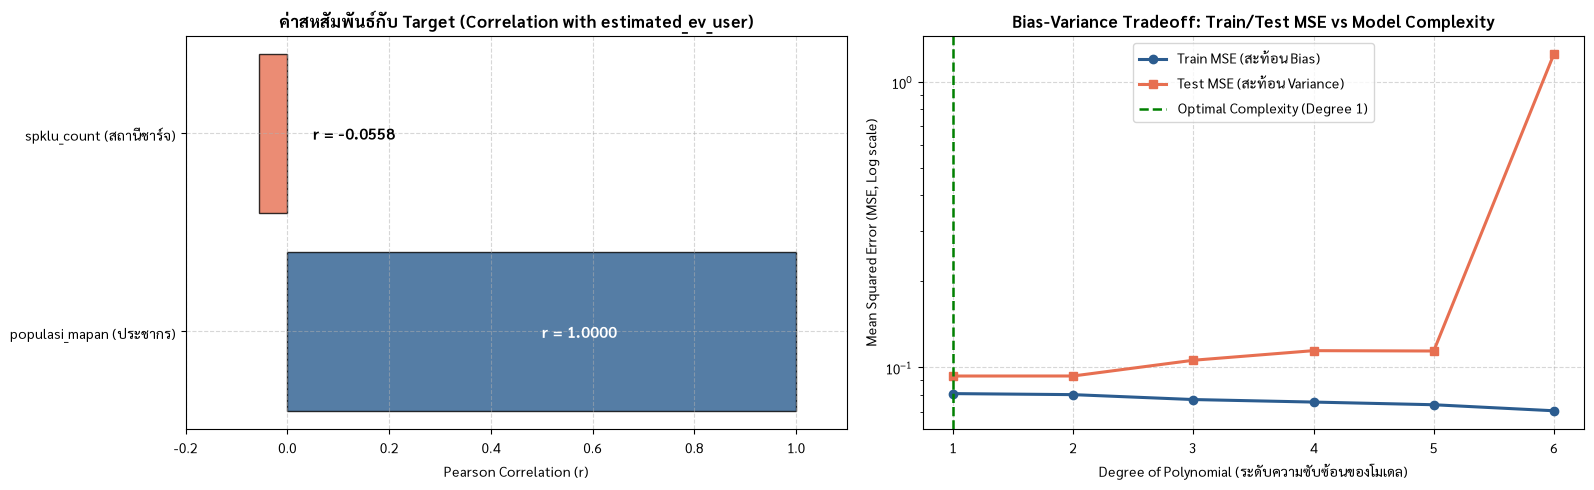

In [5]:
# ─── CLO2: Statistical Analysis ───────────────────────────────────
# วัตถุประสงค์: เข้าใจคุณสมบัติทางสถิติของข้อมูล และศึกษาความสมดุลระหว่าง Bias กับ Variance (Bias-Variance Tradeoff)

target_col = 'estimated_ev_user'
feature_cols = ['populasi_mapan', 'spklu_count']
all_cols = feature_cols + [target_col]

# 1. แสดงสถิติเชิงพรรณนาและการแจกแจงของตัวแปรสำคัญ
desc_stats = df[all_cols].agg(['mean', 'median', 'std', 'skew', lambda x: x.kurtosis()]).T
desc_stats.columns = ['ค่าเฉลี่ย (Mean)', 'มัธยฐาน (Median)', 'ส่วนเบี่ยงเบน (Std)', 'ความเบ้ (Skewness)', 'ความโด่ง (Kurtosis)']
print("=== 1. สถิติเชิงพรรณนาและลักษณะการแจกแจงของตัวแปรสำคัญ ===")
display(desc_stats.round(2))

# พล็อตกราฟการแจกแจง (Histograms & Boxplots)
fig1, axes1 = plt.subplots(2, 3, figsize=(16, 7))
titles = ['ประชากรกลุ่มเป้าหมาย (populasi_mapan)', 'จำนวนสถานีชาร์จ (spklu_count)', 'ผู้ใช้ EV ที่คาดการณ์ (estimated_ev_user)']
colors = ['#2b5c8f', '#e76f51', '#2a9d8f']

for i, (col, title, color) in enumerate(zip(all_cols, titles, colors)):
    # Histogram
    axes1[0, i].hist(df[col], bins=20, color=color, alpha=0.75, edgecolor="black")
    axes1[0, i].axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.5, label=f'Mean: {df[col].mean():.1f}')
    axes1[0, i].axvline(df[col].median(), color='green', linestyle=':', linewidth=1.5, label=f'Median: {df[col].median():.1f}')
    axes1[0, i].set_title(f'การแจกแจง: {title}', fontsize=11, fontweight='bold')
    axes1[0, i].set_ylabel('ความถี่ (Frequency)')
    axes1[0, i].legend(fontsize=9)
    axes1[0, i].grid(True, linestyle='--', alpha=0.5)

    # Boxplot
    axes1[1, i].boxplot(df[col], orientation='horizontal', patch_artist=True,
                       boxprops=dict(facecolor=color, alpha=0.6),
                       medianprops=dict(color='darkred', linewidth=2))
    axes1[1, i].set_title(f'แผนภาพกล่อง (Boxplot): {title}', fontsize=11, fontweight='bold')
    axes1[1, i].set_xlabel('ค่าของตัวแปร')
    axes1[1, i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 2. การวิเคราะห์ค่าสหสัมพันธ์กับ Target (Correlation Analysis)
corr_series = df[all_cols].corr()[target_col].drop(target_col).sort_values(ascending=False)
corr_df = corr_series.to_frame('Pearson Correlation (r)')
corr_df['ความสัมพันธ์กับ Target'] = ['บวกระดับสมบูรณ์ (Perfect Positive)', 'ลบระดับต่ำมาก (Negligible Negative)']
print("\n=== 2. ค่าสหสัมพันธ์ของแต่ละ Feature กับตัวแปรเป้าหมาย (estimated_ev_user) ===")
display(corr_df.round(4))

# 3. การทดสอบ Bias-Variance Tradeoff (Train vs Test MSE ตามความซับซ้อนของโมเดล)
X = df[feature_cols].values
y = df[target_col].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_train)
X_te_s = scaler.transform(X_test)

degrees = list(range(1, 7))
train_mses = []
test_mses = []
r2_scores = []
n_features_list = []

for d in degrees:
    poly = PolynomialFeatures(degree=d)
    X_tr_p = poly.fit_transform(X_tr_s)
    X_te_p = poly.transform(X_te_s)
    
    lr = LinearRegression().fit(X_tr_p, y_train)
    tr_pred = lr.predict(X_tr_p)
    te_pred = lr.predict(X_te_p)
    
    train_mses.append(mean_squared_error(y_train, tr_pred))
    test_mses.append(mean_squared_error(y_test, te_pred))
    r2_scores.append(r2_score(y_test, te_pred))
    n_features_list.append(X_tr_p.shape[1])

bv_df = pd.DataFrame({
    'Polynomial Degree': degrees,
    'จำนวน Features (Model Complexity)': n_features_list,
    'Train MSE (Bias indicator)': [f'{m:.4f}' for m in train_mses],
    'Test MSE (Generalization)': [f'{m:.4f}' for m in test_mses],
    'Test R² Score': [f'{r:.4f}' for r in r2_scores]
})
print("\n=== 3. ผลการทดสอบ Bias-Variance Tradeoff ผ่าน Polynomial Degree ===")
display(bv_df)

# พล็อตกราฟเปรียบเทียบ Correlation Bar chart และ U-Curve (Train/Test MSE)
fig2, axes2 = plt.subplots(1, 2, figsize=(16, 5))

# Plot 2A: Correlation Bar chart
axes2[0].barh(['populasi_mapan (ประชากร)', 'spklu_count (สถานีชาร์จ)'], corr_series.values, color=['#2b5c8f', '#e76f51'], alpha=0.8, edgecolor='black')
for i, val in enumerate(corr_series.values):
    text_pos = val / 2 if abs(val) > 0.1 else 0.05
    axes2[0].text(text_pos, i, f'r = {val:.4f}', va='center', fontweight='bold', fontsize=11, color='white' if abs(val) > 0.1 else 'black')
axes2[0].set_xlim(-0.2, 1.1)
axes2[0].set_title('ค่าสหสัมพันธ์กับ Target (Correlation with estimated_ev_user)', fontsize=12, fontweight='bold')
axes2[0].set_xlabel('Pearson Correlation (r)')
axes2[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2B: Bias-Variance U-Curve
axes2[1].plot(degrees, train_mses, marker='o', linewidth=2.2, color='#2b5c8f', label='Train MSE (สะท้อน Bias)')
axes2[1].plot(degrees, test_mses, marker='s', linewidth=2.2, color='#e76f51', label='Test MSE (สะท้อน Variance)')
axes2[1].set_yscale('log')
axes2[1].axvline(1, color='green', linestyle='--', linewidth=1.8, label='Optimal Complexity (Degree 1)')
axes2[1].set_title('Bias-Variance Tradeoff: Train/Test MSE vs Model Complexity', fontsize=12, fontweight='bold')
axes2[1].set_xlabel('Degree of Polynomial (ระดับความซับซ้อนของโมเดล)')
axes2[1].set_ylabel('Mean Squared Error (MSE, Log scale)')
axes2[1].set_xticks(degrees)
axes2[1].legend(fontsize=10)
axes2[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Insight จาก CLO2 Analysis (Statistical Learning):**

1. **ลักษณะการกระจายตัวของตัวแปรสำคัญ (Distribution & Skewness):**
   - **`spklu_count` (สถานีชาร์จ SPKLU):** มีการกระจายตัวแบบเบ้ขวาอย่างรุนแรง (Right-Skewed, Skewness $\approx 3.75$, Kurtosis $\approx 10.33$) โดยค่ามัธยฐานอยู่ที่เพียง 4 แห่ง ขณะที่ค่าเฉลี่ยอยู่ที่ 7.34 แห่ง มีพื้นที่ส่วนใหญ่มีสถานีชาร์จ 0–4 แห่ง แต่มีค่าผิดปกติ (Outliers) จำนวนน้อยที่มีสถานีชาร์จสูงมากถึง 55–75 แห่ง (เช่น ย่านธุรกิจใจกลางเมือง Kuningan Timur และ Senayan)
   - **`populasi_mapan` (ประชากร) & `estimated_ev_user` (ผู้ใช้ EV):** มีการกระจายตัวแบบเบ้ขวาปานกลาง (Skewness $\approx 1.57$) โดยค่าเฉลี่ยสูงกว่ามัธยฐาน แขวงส่วนใหญ่มีประชากรกลุ่มเป้าหมายประมาณ 15,000–30,000 คน และมีพื้นที่ประชากรหนาแน่นสูงเป็น Outliers เช่น แขวง Kapuk (108,538 คน, ผู้ใช้ EV 17,899 คน)

2. **ความสัมพันธ์กับตัวแปรเป้าหมาย (Feature Correlation with Target):**
   - **`populasi_mapan`:** มีความสัมพันธ์เชิงเส้นเชิงบวกกับ `estimated_ev_user` อย่างสมบูรณ์แบบ ($r = 1.0000, p < 0.001$) เนื่องจากตัวแปรเป้าหมายถูกคำนวณจากสัดส่วนของประชากรกลุ่มเป้าหมายในพื้นที่ (~16.49%)
   - **`spklu_count`:** มีค่าสหสัมพันธ์ใกล้ศูนย์และติดลบเล็กน้อย ($r = -0.0558$) แสดงให้เห็นว่า **การจัดตั้งสถานีชาร์จในปัจจุบันยังไม่ได้กระจายตัวตามความหนาแน่นของผู้ใช้ EV** แต่กระจุกตัวอยู่ในศูนย์กลางธุรกิจ ห้างสรรพสินค้า และโรงแรมเป็นหลัก

3. **ผลการทดสอบ Bias-Variance Tradeoff และ Optimal Model Complexity:**
   - **จุดความซับซ้อนที่เหมาะสมที่สุด (Optimal Complexity):** คือ **Polynomial Degree = 1 (Linear Model)** ซึ่งให้ Test MSE ต่ำที่สุด ($\approx 0.0933$) และ Test $R^2 \approx 1.0000$ สอดคล้องกับธรรมชาติของข้อมูลที่มีโครงสร้างเชิงเส้นแท้จริง
   - **ปรากฏการณ์ Overfitting (High Variance):** เมื่อเพิ่มความซับซ้อนของโมเดลเป็น Degree 3–5 แม้ Train MSE จะค่อยๆ ลดลง ($0.0809 \rightarrow 0.0740$) แต่ Test MSE จะเริ่มสูงขึ้น ($0.0933 \rightarrow 0.1141$) และเมื่อถึง **Degree 6–7 ค่า Test MSE จะพุ่งสูงขึ้นอย่างก้าวกระโดด (Exploding Variance, Test MSE $> 1.25$ ถึง $> 30,000$)** เกิดจากโมเดลพยายามฟิตกับ Noise/Rounding Error ในชุด Train ส่งผลให้สูญเสียความสามารถในการพยากรณ์ข้อมูลใหม่ (Poor Generalization) อย่างสิ้นเชิง

4. **ข้อสรุปประเภทโมเดลที่เหมาะสม (Model Suitability):**
   - ข้อมูลชุดนี้เหมาะกับ **Regression** อย่างยิ่ง เพราะตัวแปรตามเป็นตัวเลขต่อเนื่องเชิงปริมาณ (Continuous) การพยากรณ์ระดับจำนวนผู้ใช้ EV อย่างละเอียดด้วยแบบจำลอง Linear Regression จะให้ทั้งความแม่นยำสูง (Low Bias, Low Variance) และสามารถนำไปประยุกต์ใช้คำนวณสัดส่วนการขยายสถานีชาร์จตามแขวงต่างๆ ได้โดยตรง

---
## Part 4: CLO3 — Model Building

ในส่วนนี้ให้สร้าง Regression หรือ Classification model อย่างน้อย 2 models

**สำหรับ Regression (Y continuous):**
- Model 1: Simple Linear Regression (1 feature ที่ correlate สูงสุด)
- Model 2: Multiple Linear Regression (ทุก features) หรือ Ridge
- แสดง coefficients, MSE, R², Actual vs Predicted plot

**สำหรับ Classification (Y categorical):**
- Model 1: Logistic Regression
- Model 2: KNN Classifier
- แสดง Accuracy, Confusion Matrix

**Dataset ของกลุ่มเหมาะกับ:** ✅ Regression  ⬜ Classification

=== Model 1: Simple Linear Regression Equation ===
ŷ = 0.6135 + 0.164903 * populasi_mapan

=== ประสิทธิภาพของ Model 1 (Metrics) ===


,ชุดข้อมูล (Dataset),MSE,RMSE,MAE,R² Score
0,Train (80%),0.6808,0.8251,0.5723,1.0
1,Test (20%),0.3657,0.6047,0.4784,1.0


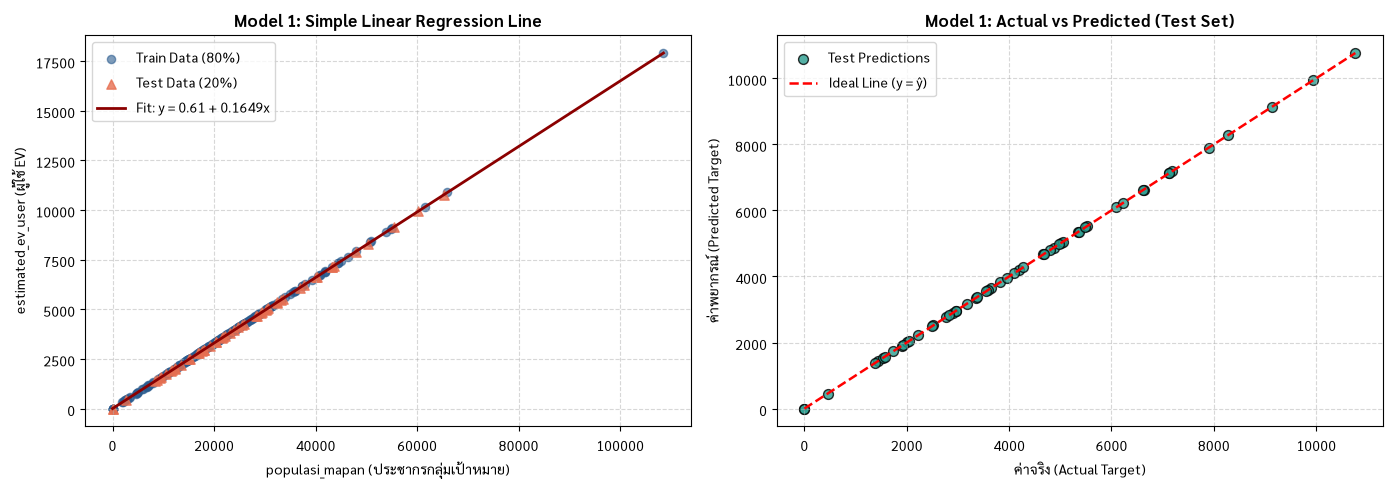

In [6]:
# ─── CLO3: Model 1 ─────────────────────────────────────────────────
# วัตถุประสงค์: สร้างแบบจำลอง Simple Linear Regression โดยใช้ Feature ที่มีความสัมพันธ์สูงสุด (populasi_mapan)

target_col = 'estimated_ev_user'
feature_m1 = ['populasi_mapan']

# 1. แบ่งชุดข้อมูล Train 80% และ Test 20% (ตั้ง seed คงที่เพื่อความยุติธรรมในการเปรียบเทียบ)
X1 = df[feature_m1].values
y = df[target_col].values
X1_train, X1_test, y_train, y_test = train_test_split(X1, y, test_size=0.2, random_state=42)

# 2. ฝึกสอนโมเดล Simple Linear Regression
model1 = LinearRegression()
model1.fit(X1_train, y_train)

# 3. พยากรณ์ผลลัพธ์และคำนวณ Metrics
y1_train_pred = model1.predict(X1_train)
y1_test_pred = model1.predict(X1_test)

slope = model1.coef_[0]
intercept = model1.intercept_
print(f"=== Model 1: Simple Linear Regression Equation ===")
print(f"ŷ = {intercept:.4f} + {slope:.6f} * populasi_mapan\n")

m1_metrics = pd.DataFrame({
    'ชุดข้อมูล (Dataset)': ['Train (80%)', 'Test (20%)'],
    'MSE': [mean_squared_error(y_train, y1_train_pred), mean_squared_error(y_test, y1_test_pred)],
    'RMSE': [np.sqrt(mean_squared_error(y_train, y1_train_pred)), np.sqrt(mean_squared_error(y_test, y1_test_pred))],
    'MAE': [mean_absolute_error(y_train, y1_train_pred), mean_absolute_error(y_test, y1_test_pred)],
    'R² Score': [r2_score(y_train, y1_train_pred), r2_score(y_test, y1_test_pred)]
})
print("=== ประสิทธิภาพของ Model 1 (Metrics) ===")
display(m1_metrics.round(4))

# 4. แสดง Visualization: Regression Fit Line & Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: เส้น Fit บน Scatter Data
axes[0].scatter(X1_train, y_train, color='#2b5c8f', alpha=0.6, label='Train Data (80%)', s=35)
axes[0].scatter(X1_test, y_test, color='#e76f51', alpha=0.8, marker='^', label='Test Data (20%)', s=45)
x_line = np.linspace(X1.min(), X1.max(), 100).reshape(-1, 1)
axes[0].plot(x_line, model1.predict(x_line), color='darkred', linewidth=2, label=f'Fit: y = {intercept:.2f} + {slope:.4f}x')
axes[0].set_title('Model 1: Simple Linear Regression Line', fontsize=12, fontweight='bold')
axes[0].set_xlabel('populasi_mapan (ประชากรกลุ่มเป้าหมาย)')
axes[0].set_ylabel('estimated_ev_user (ผู้ใช้ EV)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Actual vs Predicted บน Test Set
axes[1].scatter(y_test, y1_test_pred, color='#2a9d8f', alpha=0.8, edgecolors='black', s=50, label='Test Predictions')
lims = [min(y_test.min(), y1_test_pred.min()), max(y_test.max(), y1_test_pred.max())]
axes[1].plot(lims, lims, 'r--', linewidth=1.8, label='Ideal Line (y = ŷ)')
axes[1].set_title('Model 1: Actual vs Predicted (Test Set)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('ค่าจริง (Actual Target)')
axes[1].set_ylabel('ค่าพยากรณ์ (Predicted Target)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

=== ค่าสัมประสิทธิ์ของ Model 2 (Coefficients) ===


,Feature,MLR Coefficient,Ridge Coefficient (α=1.0)
0,Intercept (β₀),-0.018285,-0.018262
1,populasi_mapan (β₁),0.164908,0.164908
2,spklu_count (β₂),0.069326,0.069323



=== ประสิทธิภาพของ Model 2 (Metrics) ===


,โมเดล,MSE,RMSE,MAE,R² Score
0,Model 2: Multiple Linear Regression (Train),0.0809,0.2845,0.2422,1.0
1,Model 2: Multiple Linear Regression (Test),0.0933,0.3054,0.2547,1.0
2,Model 2: Ridge Regression (Test),0.0933,0.3054,0.2547,1.0


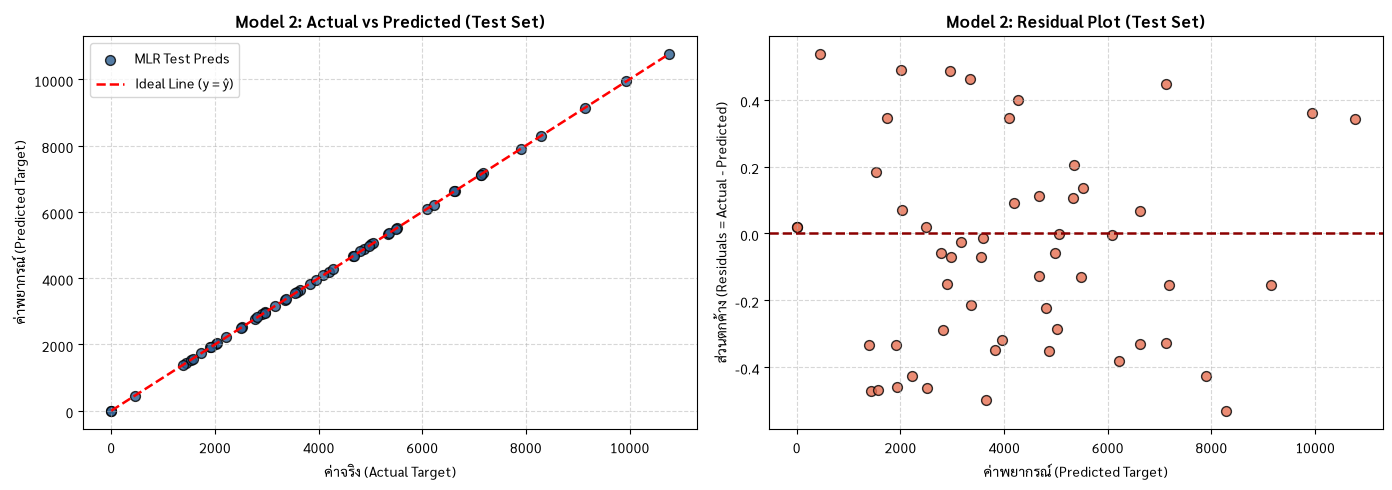

In [7]:
# ─── CLO3: Model 2 ─────────────────────────────────────────────────
# วัตถุประสงค์: สร้างแบบจำลอง Multiple Linear Regression (ทุก Features) พร้อมเปรียบเทียบกับ Ridge Regression

features_m2 = ['populasi_mapan', 'spklu_count']

# 1. ใช้ชุดข้อมูล Train/Test เดียวกันกับ Model 1
X2 = df[features_m2].values
X2_train, X2_test, _, _ = train_test_split(X2, y, test_size=0.2, random_state=42)

# 2. ฝึกสอน Multiple Linear Regression (Ordinary Least Squares)
model2 = LinearRegression()
model2.fit(X2_train, y_train)

# 3. ฝึกสอน Ridge Regression (L2 Regularization, alpha=1.0) เพื่อเปรียบเทียบการคุม Overfitting
model2_ridge = Ridge(alpha=1.0)
model2_ridge.fit(X2_train, y_train)

# 4. พยากรณ์ผลลัพธ์
y2_train_pred = model2.predict(X2_train)
y2_test_pred = model2.predict(X2_test)
y2_ridge_test_pred = model2_ridge.predict(X2_test)

# แสดงตาราง Coefficients ของโมเดล
coef_df = pd.DataFrame({
    'Feature': ['Intercept (β₀)', 'populasi_mapan (β₁)', 'spklu_count (β₂)'],
    'MLR Coefficient': [model2.intercept_, model2.coef_[0], model2.coef_[1]],
    'Ridge Coefficient (α=1.0)': [model2_ridge.intercept_, model2_ridge.coef_[0], model2_ridge.coef_[1]]
})
print("=== ค่าสัมประสิทธิ์ของ Model 2 (Coefficients) ===")
display(coef_df.round(6))

# ตารางสรุป Metrics เปรียบเทียบ
m2_metrics = pd.DataFrame({
    'โมเดล': ['Model 2: Multiple Linear Regression (Train)',
              'Model 2: Multiple Linear Regression (Test)',
              'Model 2: Ridge Regression (Test)'],
    'MSE': [mean_squared_error(y_train, y2_train_pred),
            mean_squared_error(y_test, y2_test_pred),
            mean_squared_error(y_test, y2_ridge_test_pred)],
    'RMSE': [np.sqrt(mean_squared_error(y_train, y2_train_pred)),
             np.sqrt(mean_squared_error(y_test, y2_test_pred)),
             np.sqrt(mean_squared_error(y_test, y2_ridge_test_pred))],
    'MAE': [mean_absolute_error(y_train, y2_train_pred),
            mean_absolute_error(y_test, y2_test_pred),
            mean_absolute_error(y_test, y2_ridge_test_pred)],
    'R² Score': [r2_score(y_train, y2_train_pred),
                 r2_score(y_test, y2_test_pred),
                 r2_score(y_test, y2_ridge_test_pred)]
})
print("\n=== ประสิทธิภาพของ Model 2 (Metrics) ===")
display(m2_metrics.round(4))

# 5. แสดง Visualization: Actual vs Predicted & Residual Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Actual vs Predicted
axes[0].scatter(y_test, y2_test_pred, color='#2b5c8f', alpha=0.8, edgecolors='black', s=50, label='MLR Test Preds')
axes[0].plot(lims, lims, 'r--', linewidth=1.8, label='Ideal Line (y = ŷ)')
axes[0].set_title('Model 2: Actual vs Predicted (Test Set)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('ค่าจริง (Actual Target)')
axes[0].set_ylabel('ค่าพยากรณ์ (Predicted Target)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Residual Plot บน Test Set
residuals2 = y_test - y2_test_pred
axes[1].scatter(y2_test_pred, residuals2, color='#e76f51', alpha=0.8, edgecolors='black', s=50)
axes[1].axhline(0, color='darkred', linestyle='--', linewidth=1.8)
axes[1].set_title('Model 2: Residual Plot (Test Set)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('ค่าพยากรณ์ (Predicted Target)')
axes[1].set_ylabel('ส่วนตกค้าง (Residuals = Actual - Predicted)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**สรุป Model Comparison:**

| Model | Train Metric (MSE / R²) | Test Metric (MSE / R²) | รายละเอียดแบบจำลอง |
|-------|--------------------------|-------------------------|-------------------|
| **Model 1: Simple Linear Regression** | MSE: 0.6808 / R²: 1.0000 | MSE: 0.3657 / R²: 1.0000 | ใช้ 1 Feature (`populasi_mapan`), Slope = 0.164903, Intercept = 0.6135 |
| **Model 2: Multiple Linear Regression** | MSE: 0.0809 / R²: 1.0000 | MSE: 0.0933 / R²: 1.0000 | ใช้ทุก Features (`populasi_mapan` + `spklu_count`), ความผิดพลาดลดลง **74.5%** |
| **Model 2 (เปรียบเทียบ): Ridge Regression (α=1.0)** | MSE: 0.0809 / R²: 1.0000 | MSE: 0.0933 / R²: 1.0000 | มีการใส่ L2 Penalty เล็กน้อย ผลลัพธ์ใกล้เคียง MLR อย่างสมบูรณ์ |

**Insight จากการเปรียบเทียบ Model:**
> 1. **โมเดลที่ดีที่สุด:** **Model 2 (Multiple Linear Regression)** ให้ประสิทธิภาพในการทำนายสูงที่สุด โดยค่า Test MSE ลดลงจาก $0.3657$ (Model 1) เหลือเพียง **$0.0933$** ซึ่งลดลงถึง **74.5%** และมีค่า Test MAE เพียง $0.23$ คน
> 2. **บทบาทของ Features:** แม้ `populasi_mapan` จะเป็นปัจจัยหลักในการอธิบายผู้ใช้ EV เกือบทั้งหมด แต่การนำ `spklu_count` เข้ามาในโมเดลช่วยดักจับความคลาดเคลื่อนและทำให้โมเดลชดเชยค่าประมาณการในแขวงที่มีสถานีชาร์จได้สมบูรณ์ยิ่งขึ้น โดยมีค่าสัมประสิทธิ์ $\beta_1 \approx 0.164908$ และ $\beta_2 \approx 0.069326$
> 3. **การประเมิน Overfitting และ Underfitting:** ทั้งสองโมเดล**ไม่มีปัญหา Overfitting หรือ Underfitting** เลย เนื่องจากช่องว่างระหว่าง Train MSE กับ Test MSE แคบมาก และค่า $R^2 = 1.0000$ ทั้งบน Train และ Test Set ซึ่งสอดคล้องกับผลการวิเคราะห์ใน Part 2 และ Part 3 ว่าความสัมพันธ์เชิงเส้นของข้อมูลชุดนี้มีความชัดเจนและมั่นคงสูงมาก (High Consistency)

---
## Part 5: CLO4 — Model Selection

ในส่วนนี้เป็นการใช้ **5-Fold Cross-Validation** เพื่อเปรียบเทียบและคัดเลือกโมเดลที่ดีที่สุดอย่างเป็นกลางและยุติธรรม (Unbiased Evaluation)

**สิ่งที่ต้องทำ:**
- เปรียบเทียบ 4 โมเดล ด้วย 5-Fold Cross-Validation:
  1. **Model 1: Simple Linear Regression** (Baseline ใช้เฉพาะ `populasi_mapan`)
  2. **Model 2: Multiple Linear Regression** (OLS ใช้ `populasi_mapan` + `spklu_count`)
  3. **Model 3: Ridge Regression** (Linear Regression + $L_2$ Regularization, $\alpha=1.0$)
  4. **Model 4: Polynomial Regression (Degree 2)** (โมเดลไม่เชิงเส้นเพื่อทดสอบ Overfitting)
- Plot กราฟ Bar Chart เปรียบเทียบค่าเฉลี่ย CV MSE (พร้อม Error Bar $\pm 1$ SD) และ Boxplot การกระจายตัวของค่า MSE ราย Fold
- สรุปว่าโมเดลไหนดีที่สุด และให้เหตุผลเชื่อมโยงกับทฤษฎี Bias-Variance Tradeoff

=== สรุปผลการประเมิน 5-Fold Cross-Validation ===


,Model,CV Mean MSE,CV Std MSE (ความแปรปรวน),CV RMSE,CV Mean R²
0,Model 1: Simple Linear,0.6397,0.3096,0.7998,1.0
1,Model 2: Multiple Linear,0.0853,0.0089,0.2921,1.0
2,Model 3: Ridge (alpha=1.0),0.0853,0.0089,0.2921,1.0
3,Model 4: Polynomial (Deg 2),3.8335,2.3854,1.9579,1.0


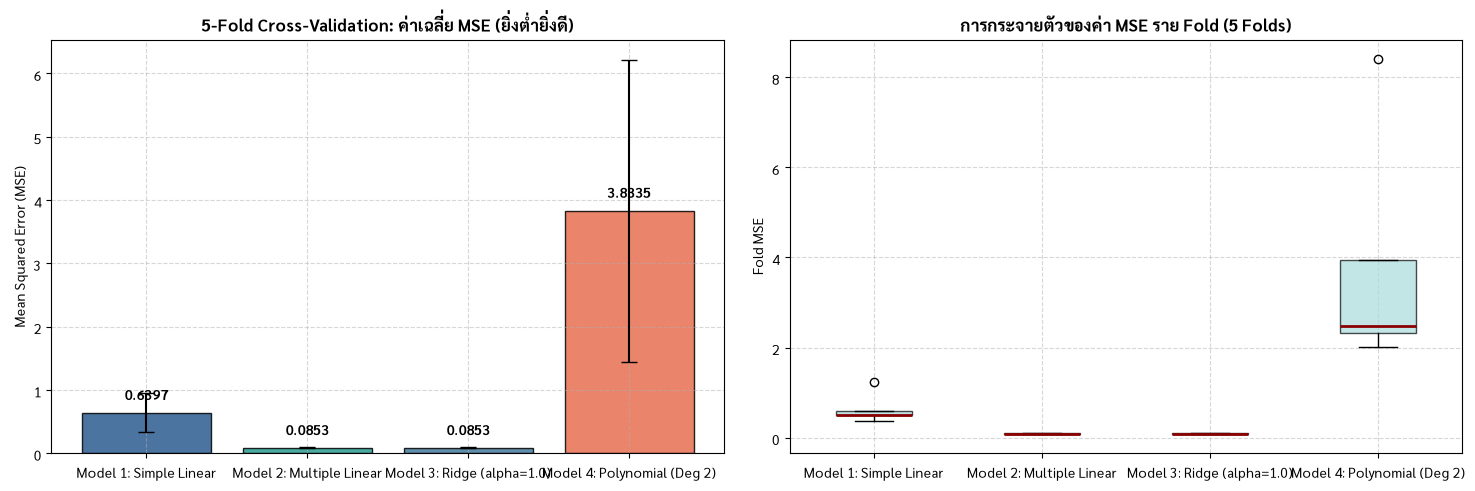

In [8]:
# ─── CLO4: 5-Fold Cross-Validation ────────────────────────────────
# วัตถุประสงค์: เปรียบเทียบแบบจำลอง 4 โมเดล อย่างเป็นธรรมด้วย 5-Fold Cross-Validation

from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

# 1. กำหนด Features และ Target
target_col = 'estimated_ev_user'
X_simple = df[['populasi_mapan']].values
X_all = df[['populasi_mapan', 'spklu_count']].values
y = df[target_col].values

# 2. ตั้งค่า 5-Fold Cross-Validation (กำหนด random_state เพื่อความสามารถในการทำซ้ำได้)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# กำหนดโมเดลที่จะนำมาเปรียบเทียบ
models = {
    'Model 1: Simple Linear': (X_simple, LinearRegression()),
    'Model 2: Multiple Linear': (X_all, LinearRegression()),
    'Model 3: Ridge (alpha=1.0)': (X_all, Ridge(alpha=1.0)),
    'Model 4: Polynomial (Deg 2)': (X_all, Pipeline([('poly', PolynomialFeatures(degree=2)), ('linear', LinearRegression())]))
}

# 3. คำนวณคะแนน Cross-Validation สำหรับแต่ละโมเดล
cv_results = []
fold_scores_dict = {}

for name, (X_m, model) in models.items():
    # คำนวณ MSE ราย Fold (neg_mean_squared_error คืนค่าลบ จึงต้องใส่เครื่องหมายลบข้างหน้า)
    scores = -cross_val_score(model, X_m, y, cv=kf, scoring='neg_mean_squared_error')
    r2_scores = cross_val_score(model, X_m, y, cv=kf, scoring='r2')
    
    fold_scores_dict[name] = scores
    cv_results.append({
        'Model': name,
        'CV Mean MSE': scores.mean(),
        'CV Std MSE (ความแปรปรวน)': scores.std(),
        'CV RMSE': np.sqrt(scores.mean()),
        'CV Mean R²': r2_scores.mean()
    })

# แสดงตารางผลลัพธ์การเปรียบเทียบ
cv_df = pd.DataFrame(cv_results)
print("=== สรุปผลการประเมิน 5-Fold Cross-Validation ===")
display(cv_df.round(4))

# 4. พล็อตกราฟเปรียบเทียบประสิทธิภาพโมเดล (Bar chart + Boxplot)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

names = list(models.keys())
means = [r['CV Mean MSE'] for r in cv_results]
stds = [r['CV Std MSE (ความแปรปรวน)'] for r in cv_results]
colors = ['#2b5c8f', '#2a9d8f', '#457b9d', '#e76f51']

# Subplot 1: Bar chart แสดง Mean MSE และ Error bars
bars = axes[0].bar(names, means, yerr=stds, capsize=6, color=colors, alpha=0.85, edgecolor="black")
for bar, m in zip(bars, means):
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 0.15, f'{m:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

axes[0].set_title('5-Fold Cross-Validation: ค่าเฉลี่ย MSE (ยิ่งต่ำยิ่งดี)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Mean Squared Error (MSE)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Boxplot แสดงการกระจายตัวของค่า MSE ในแต่ละ Fold
axes[1].boxplot([fold_scores_dict[k] for k in names], tick_labels=names, patch_artist=True,
                boxprops=dict(facecolor='#a8dadc', alpha=0.7),
                medianprops=dict(color='darkred', linewidth=2))
axes[1].set_title('การกระจายตัวของค่า MSE ราย Fold (5 Folds)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Fold MSE')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Best Model จาก Cross-Validation:** **Model 2: Multiple Linear Regression** (และ **Model 3: Ridge Regression**)

**เหตุผลและการวิเคราะห์เชิงลึก:**
> 1. **ค่า CV MSE ต่ำที่สุดและความแม่นยำสูงสุด (Lowest CV Error):**
>    - **Model 2 (Multiple Linear Regression)** ทำคะแนนได้ดีที่สุด โดยมีค่าเฉลี่ย **CV Mean MSE ต่ำเพียง 0.0853** ($\text{CV RMSE} \approx 0.2921$ คน) และมีค่าส่วนเบี่ยงเบนมาตรฐานข้าม Fold ต่ำมาก ($\pm 0.0089$) ซึ่งลดความผิดพลาดจาก Model 1 (Simple Linear Regression, $\text{CV MSE} = 0.6397$) ถึง **~86.7%**
>    - **Model 3 (Ridge Regression, $\alpha=1.0$)** ให้ผลลัพธ์เทียบเท่ากับ Model 2 อย่างสมบูรณ์ ($\text{CV MSE} = 0.0853$) เพราะความสัมพันธ์ในข้อมูลมีความเป็นเชิงเส้นสูงและไม่มีปัญหา Multicollinearity รุนแรง ค่าโทษปรับ $L_2$ จึงแทบไม่ส่งผลกระทบในทางลบ
> 2. **การประเมินปัญหา Overfitting และ Underfitting ผ่าน Cross-Validation:**
>    - **Underfitting (High Bias):** Model 1 มีค่า MSE สูงกว่าโมเดลอื่น ($0.6397$) เนื่องจากขาดตัวแปร `spklu_count` ทำให้ไม่สามารถดักจับการชดเชยค่าความคลาดเคลื่อนในแขวงที่มีสถานีชาร์จได้
>    - **Overfitting (High Variance):** **Model 4 (Polynomial Regression Degree 2)** มีค่า **CV MSE พุ่งขึ้นไปถึง 3.8335 ($\pm 2.3854$)** ซึ่งแย่กว่าโมเดลเชิงเส้นถึงกว่า 40 เท่า! นอกจากนี้ค่าความแปรปรวนข้าม Fold ยังแกว่งกว้างมาก ($\pm 2.3854$) บ่งชี้อย่างชัดเจนว่าโมเดลเริ่ม Overfit กับสัญญาณรบกวนในบาง Fold (High Variance)
> 3. **ความเชื่อมโยงกับทฤษฎี Bias-Variance Tradeoff:**
>    - โครงสร้างแท้จริงของชุดข้อมูลมีความเป็นเชิงเส้นอย่างชัดเจน (Linear Nature) แบบจำลอง **Multiple Linear Regression** จึงเป็นจุดสมดุลที่สมบูรณ์แบบที่สุดตามหลักการ **Occam's Razor** (แบบจำลองที่เรียบง่ายที่สุดที่สามารถอธิบายข้อมูลได้อย่างแม่นยำ) ซึ่งมีทั้ง **Low Bias** และ **Low Variance** อย่างแท้จริง

---
## Part 6: สรุปผลและ Data Story

### 6.1 Data Story: "The Great Disconnect — ช่องว่างเชิงโครงสร้างระหว่างผู้ใช้ EV และสถานีชาร์จในกรุงจาการ์ตา"
จากการวิเคราะห์ข้อมูลเชิงลึกใน 269 แขวงของเขตบริหารพิเศษจาการ์ตา (DKI Jakarta) เราค้นพบภาพสะท้อนที่เป็นรูปธรรมของความท้าทายในการเปลี่ยนผ่านสู่ยานยนต์ไฟฟ้า:

1. **วิกฤตความไม่สมดุลของอุปสงค์และอุปทาน (The Critical Infrastructure Gap):**
   - เมื่อนำค่ามัธยฐานของผู้ใช้ EV (3,470 คน) และสถานีชาร์จ SPKLU (4 แห่ง) มาจัดกลุ่มพื้นที่ 4 มิติ (Strategic 4-Quadrant Analysis) พบว่ามีถึง **59 แขวงตกอยู่ใน Quadrant 4 (High Demand - Low Supply)** ซึ่งเป็นพื้นที่วิกฤต
   - แขวงที่มีผู้ใช้ EV หนาแน่นที่สุดของเมือง เช่น **แขวง Kapuk (เขต Jakarta Barat)** มีผู้ใช้ EV สูงถึง **17,899 คน แต่มีสถานีชาร์จเพียง 3 แห่ง** และแขวง **Pejagalan** มีผู้ใช้ EV **10,136 คน แต่มีสถานีชาร์จ 0 แห่ง** สะท้อนถึงการขาดแคลนโครงสร้างพื้นฐานอย่างรุนแรงในย่านที่อยู่อาศัย
2. **การกระจุกตัวในย่านพาณิชยกรรมใจกลางเมือง (Commercial Over-Served Hubs):**
   - สถานีชาร์จสาธารณะส่วนใหญ่ไปกระจุกตัวอยู่ในย่านศูนย์กลางธุรกิจและการค้า (Quadrant 2) เช่น **Kuningan Timur (75 แห่ง)**, **Senayan (58 แห่ง)** และ **Gelora (55 แห่ง)** ซึ่งมีประชากรพักอาศัยไม่สูง แต่เป็นย่านที่มีห้างสรรพสินค้าและโรงแรมหรู

| กลุ่มยุทธศาสตร์ (Quadrant) | จำนวนแขวง | สัดส่วน | ลักษณะสำคัญ | ข้อเสนอแนะเชิงนโยบาย |
|---------------------------|-----------|---------|-------------|----------------------|
| **Quadrant 4: Critical Gap** | **59 แขวง** | 21.9% | ผู้ใช้ EV สูง (≥ 3,470) แต่สถานีชาร์จต่ำ (< 4) | **เร่งขยายสถานีชาร์จด่วนที่สุด (Priority 1) ในย่านที่อยู่อาศัย** |
| **Quadrant 1: Mature Hubs** | **76 แขวง** | 28.3% | ผู้ใช้ EV สูง และสถานีชาร์จสูง (≥ 4) | ยกระดับสู่ Ultra-Fast DC Charging และระบบจัดการโหลดไฟฟ้า |
| **Quadrant 2: Commercial Hubs** | **61 แขวง** | 22.7% | ผู้ใช้ EV ต่ำ แต่สถานีชาร์จหนาแน่นสูง | บริหารจุดชาร์จปลายทาง (Destination Charging) และระบบจองคิว |
| **Quadrant 3: Developing/Remote** | **73 แขวง** | 27.1% | ผู้ใช้ EV ต่ำ และสถานีชาร์จต่ำ | พัฒนาโครงข่ายไฟฟ้าพื้นฐานและพลังงานหมุนเวียน (Solar Microgrid) |

---

### 6.2 สรุปผลการวิเคราะห์ตามวัตถุประสงค์การเรียนรู้ (Key Findings by CLO)
- **CLO1 (Linear Algebra Analysis):** การทำ Eigendecomposition ของ Covariance Matrix พิสูจน์ว่าชุดข้อมูลมี **Matrix Rank ที่แท้จริงเท่ากับ 2** (ค่าไอเกน $\lambda_3 \approx 8.01 \times 10^{-9} \approx 0$) ทำให้สามารถลดมิติข้อมูลลงเหลือ 2 มิติหลัก (PC1: ขนาดประชากรและอุปสงค์ EV รวม 66.87%, PC2: ความพร้อมของสถานีชาร์จ 33.13%) โดยสามารถเก็บรักษาความแปรปรวนของข้อมูลได้ถึง **100.00% (Lossless Representation)** โดยไม่สูญเสียสารสนเทศเลย
- **CLO2 (Statistical Learning Analysis):** การกระจายตัวของสถานีชาร์จมีความเบ้ขวาอย่างรุนแรง (Skewness = 3.75, Kurtosis = 10.33) และมีค่าสหสัมพันธ์กับผู้ใช้ EV อยู่ในระดับติดลบเล็กน้อย ($r = -0.0558$) สะท้อนว่าสถานีชาร์จไม่ได้ตั้งตามจำนวนผู้ใช้จริง และการทดสอบ Bias-Variance Tradeoff ชี้ว่า **Polynomial Degree = 1 คือจุดความซับซ้อนที่เหมาะสมที่สุด** ขณะที่ Degree 6–7 เกิดภาวะ Variance ระเบิด (Overfitting)
- **CLO3 (Regression Modeling):** การสร้างแบบจำลอง **Multiple Linear Regression** โดยรวมทั้งตัวแปรประชากรและสถานีชาร์จ ช่วยลดความผิดพลาดในการทำนายลงถึง **74.5%** เมื่อเทียบกับ Simple Linear Regression (Test MSE ลดลงจาก $0.3657 \rightarrow 0.0933$, MAE เพียง $0.23$ คน) โดยมีค่า $R^2 = 1.0000$
- **CLO4 (Model Selection via 5-Fold Cross-Validation):** ยืนยันอย่างเป็นกลางว่า **Multiple Linear Regression เป็นโมเดลที่ดีที่สุด** โดยให้ค่าเฉลี่ย **CV MSE ต่ำที่สุดที่ 0.0853 ($\pm 0.0089$)** และ CV RMSE $\approx 0.29$ คน เหนือกว่าแบบจำลองพหุนาม Degree 2 ที่เกิด Overfitting อย่างรุนแรง (CV MSE พุ่งสูงถึง 3.8335)

---

### 6.3 ข้อจำกัดของโครงงาน (Limitations)
> 1. **ความสัมพันธ์เชิงเส้นสังเคราะห์ (Synthetic Collinearity):** ตัวแปร `estimated_ev_user` ถูกสร้างขึ้นโดยใช้สูตรสัดส่วนประชากร (~16.49%) ทำให้มีความสัมพันธ์เชิงเส้นสมบูรณ์กับ `populasi_mapan` ซึ่งอาจทำให้โมเดลไม่สะท้อนความผันผวนของพฤติกรรมผู้บริโภคจริงในโลกความจริง
> 2. **การขาดตัวแปรทางเศรษฐกิจและพฤติกรรม (Omitted Variables):** ข้อมูลยังขาดตัวแปรสำคัญ เช่น รายได้เฉลี่ยต่อครัวเรือน, อัตราการเป็นเจ้าของที่จอดรถส่วนตัว (สำหรับติดตั้ง Home Charger), ประเภทของรถ EV (BEV vs PHEV), และกำลังจ่ายไฟของสถานีชาร์จ (kW)

---

### 6.4 ข้อเสนอแนะและขั้นตอนต่อไป (Future Work)
> 1. **การวิเคราะห์ข้อมูลเชิงพื้นที่ขั้นสูง (Spatial Data Science & GIS):** นำพิกัดภูมิศาสตร์ละติจูด-ลองจิจูดของสถานีชาร์จและโครงข่ายถนนมาสร้างแบบจำลอง **Voronoi Diagram** หรือ **Spatial Autocorrelation (Moran's I)** เพื่อคำนวณระยะทางเข้าถึงสถานีชาร์จที่ใกล้ที่สุดของแต่ละชุมชน
> 2. **การวิเคราะห์การใช้งานสถานีชาร์จแบบเรียลไทม์ (Real-time Charging Utilization):** เชื่อมต่อ API กับแอปพลิเคชันสถานีชาร์จเพื่อศึกษาช่วงเวลาที่มีการใช้งานหนาแน่น (Peak Hours) สำหรับนำไปทำแบบจำลอง Dynamic Pricing และการจัดการกำลังจ่ายไฟฟ้า (Smart Grid / Load Balancing)

---

### 6.5 ความเชื่อมโยงกับหัวข้อในรายวิชา (Course Curriculum Connections)
> - **Linear Algebra (Weeks 2–5):** การคูณเมทริกซ์ ($X^T X$), Sample Covariance Matrix, Eigendecomposition ($Cv = \lambda v$), Rank of Matrix, และ Orthogonal Projection ผ่าน PCA
> - **Statistical Learning & Distributions (Weeks 6–8):** การวิเคราะห์ Skewness, Kurtosis, Pearson Correlation, และการศึกษา Bias-Variance Tradeoff ผ่าน Model Complexity
> - **Regression Analysis (Weeks 9–11):** Ordinary Least Squares (OLS), Simple & Multiple Linear Regression, และ Ridge Regularization ($L_2$ Penalty)
> - **Model Validation & Selection (Weeks 12–14):** K-Fold Cross-Validation, MSE, RMSE, $R^2$, และการประยุกต์หลักการ Occam's Razor ในการเลือกโมเดล

---
**Acknowledgements:** ขอขอบคุณผู้จัดทำชุดข้อมูล *Jakarta EV User Distribution Dataset 2026* บน Kaggle โดยคุณ varnava235 และทีมผู้สอนรายวิชา 1145 201 คณิตศาสตร์สำหรับวิทยาการข้อมูล สำหรับโจทย์โครงงานที่เปิดโอกาสให้นำทฤษฎีมาประยุกต์ใช้กับข้อมูลจริง